# 서울 공유자전거 데이터로 KNN 직접 구현하기

입력은 **Hour, Temperature, Humidity**, 정답은 대여량에 따른 **Low, Medium, High**입니다.
pandas는 CSV 읽기와 데이터 정리에만 사용하고, 데이터 분할·정규화·거리 계산·이웃 선택·다수결·정확도 계산은 파이썬으로 직접 구현합니다. sklearn은 사용하지 않습니다.

1. CSV를 읽고 대여량을 세 등급으로 변환합니다.
2. 같은 난수 시드로 데이터를 섞어 학습 80%, 테스트 20%로 나눕니다.
3. 학습 데이터의 최솟값·최댓값으로 두 데이터셋을 Min-Max 정규화합니다.
4. K = 1, 3, 5, 7, 9의 정확도를 같은 테스트 데이터에서 비교합니다.
5. 그래프를 화면에 출력하고 PNG 파일로 저장합니다.

**실행:** VS Code에서 이 노트북을 열고, 우측 상단 커널로 이 폴더의 `.venv/Scripts/python.exe`를 선택한 다음 **모두 실행**을 누르세요. 환경 설치 방법은 같은 폴더의 README.md에 있습니다.

**데이터 출처:** [UCI Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand). 원본 `SeoulBikeData.csv`를 이 노트북과 같은 폴더에 두었습니다.

## 1. 라이브러리와 실행 설정

난수 시드를 고정하면 셀을 다시 실행해도 동일한 학습/테스트 분할을 얻습니다.
CSV의 실제 열 이름인 `Temperature(°C)`, `Humidity(%)`는 읽을 때 간단한 이름으로 바꿉니다.

In [1]:
import math
import random
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

FEATURE_COLUMNS = ["Hour", "Temperature", "Humidity"]
TARGET_COLUMN = "Rented Bike Count"
K_VALUES = [1, 3, 5, 7, 9]
RANDOM_SEED = 42

# 노트북 폴더, bigdata_programing 폴더, 프로젝트 루트에서 실행할 수 있습니다.
CSV_PATH = Path("SeoulBikeData.csv")
for folder in [Path("."), Path("bike_knn_project"),
               Path("bigdata_programing/bike_knn_project")]:
    candidate = folder / "SeoulBikeData.csv"
    if candidate.is_file():
        CSV_PATH = candidate.resolve()
        break

## 2. CSV 읽기와 정답 등급 만들기

33%씩 나눈다는 뜻을 **정확히 3등분(1/3, 2/3 분위수)**으로 해석합니다.
전체 유효 데이터에서 경계값을 계산해 분류 문제의 정답을 정의합니다.

- Low: 대여량 ≤ 1/3 분위수
- Medium: 1/3 분위수 < 대여량 ≤ 2/3 분위수
- High: 대여량 > 2/3 분위수

같은 대여량은 같은 등급으로 묶으므로 경계에 중복값이 있으면 각 등급의 개수가 정확히 같지는 않습니다.
이 경계값은 정답 정의에만 사용하며, **Rented Bike Count는 입력 변수에 포함하지 않습니다.**

In [2]:
def load_data(csv_path):
    """CSV에서 필요한 네 열을 읽고 숫자가 아닌 값과 결측치를 정리합니다."""
    if not csv_path.is_file():
        raise FileNotFoundError(
            "SeoulBikeData.csv를 노트북과 같은 폴더에 넣거나 CSV_PATH를 수정하세요."
        )

    # UCI 원본에는 도 기호(°)가 있어 UTF-8 읽기가 실패할 수 있습니다.
    # 이때 다른 인코딩으로 다시 읽습니다. latin1은 UCI 원본에 대응합니다.
    for encoding in ["utf-8-sig", "latin1"]:
        try:
            data = pd.read_csv(csv_path, encoding=encoding)
            break
        except UnicodeDecodeError:
            continue

    data.columns = data.columns.str.strip()
    data = data.rename(columns={
        "Temperature(°C)": "Temperature",
        "Humidity(%)": "Humidity",
    })

    required_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
    missing_columns = [name for name in required_columns if name not in data.columns]
    if missing_columns:
        raise ValueError(f"CSV에 필요한 열이 없습니다: {missing_columns}")

    # 필요한 열만 남깁니다. 변환할 수 없는 문자열은 NaN(결측치)이 됩니다.
    data = data[required_columns].copy()
    for column in required_columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    data = data.replace([float("inf"), float("-inf")], float("nan"))

    original_count = len(data)
    data = data.dropna().reset_index(drop=True)
    print(f"사용할 데이터: {len(data):,}행 (제외한 결측/비정상 행: {original_count - len(data):,})")
    if len(data) < 12:
        raise ValueError("8:2 분할 후 K=9까지 비교하려면 최소 12행이 필요합니다.")
    return data


def make_labels(data):
    """대여량의 분위수를 구하고 각 행에 Low, Medium, High 정답을 붙입니다."""
    low_boundary = data[TARGET_COLUMN].quantile(1 / 3)
    high_boundary = data[TARGET_COLUMN].quantile(2 / 3)

    labels = []
    for count in data[TARGET_COLUMN]:
        if count <= low_boundary:
            labels.append("Low")
        elif count <= high_boundary:
            labels.append("Medium")
        else:
            labels.append("High")

    print(f"Low 경계값: {low_boundary:.2f}, Medium 경계값: {high_boundary:.2f}")
    for label in ["Low", "Medium", "High"]:
        print(f"  {label:6s}: {labels.count(label):,}행")
    return labels

## 3. 학습/테스트를 8:2로 분할

행 번호를 섞은 뒤 앞 80%를 학습에, 나머지를 테스트에 사용합니다.
입력과 정답에 **같은 행 번호**를 적용해야 둘의 짝이 유지됩니다.
행 수가 5의 배수가 아니라면 학습 데이터 수는 80%를 계산한 뒤 소수점 아래를 버립니다.

In [3]:
def split_data(features, labels, train_ratio=0.8, seed=42):
    """입력과 정답의 짝을 유지하며 무작위로 학습/테스트 데이터를 나눕니다."""
    if len(features) != len(labels):
        raise ValueError("입력 데이터와 정답의 개수가 같아야 합니다.")
    if not 0 < train_ratio < 1:
        raise ValueError("학습 비율은 0과 1 사이여야 합니다.")

    indices = list(range(len(features)))
    random.Random(seed).shuffle(indices)
    split_index = int(len(indices) * train_ratio)
    if split_index == 0 or split_index == len(indices):
        raise ValueError("학습 데이터와 테스트 데이터가 각각 한 행 이상 필요합니다.")

    train_indices = indices[:split_index]
    test_indices = indices[split_index:]
    X_train = [features[i] for i in train_indices]
    X_test = [features[i] for i in test_indices]
    y_train = [labels[i] for i in train_indices]
    y_test = [labels[i] for i in test_indices]
    return X_train, X_test, y_train, y_test

## 4. Min-Max 정규화

열마다 단위와 범위가 다르므로 `(현재 값 - 최솟값) / (최댓값 - 최솟값)`으로 변환합니다.
**먼저 분할하고 학습 데이터에서만 최솟값·최댓값을 구합니다.**
테스트에도 같은 기준을 적용해야 테스트 데이터의 정보가 학습 과정에 섞이지 않습니다.

학습 데이터는 보통 0~1 범위로 바뀝니다. 테스트 값이 학습 범위를 벗어나면 결과가 0 미만이나 1 초과일 수 있으며, 이 값을 강제로 자르지 않습니다.
학습 데이터에서 모든 값이 같은 열은 0으로 처리합니다.

In [4]:
def get_min_max(X_train):
    """학습 데이터의 각 열에서 최솟값과 최댓값을 직접 구합니다."""
    minimums = []
    maximums = []
    for column_index in range(len(X_train[0])):
        column_values = [row[column_index] for row in X_train]
        minimums.append(min(column_values))
        maximums.append(max(column_values))
    return minimums, maximums


def min_max_normalize(features, minimums, maximums):
    """이미 구한 학습 기준으로 입력 데이터를 정규화합니다."""
    normalized_data = []
    for row in features:
        normalized_row = []
        for column_index in range(len(row)):
            value_range = maximums[column_index] - minimums[column_index]
            if value_range == 0:
                # 같은 값만 있는 열은 구분에 도움이 없고, 0으로 나눌 수도 없습니다.
                normalized_value = 0.0
            else:
                normalized_value = (
                    (row[column_index] - minimums[column_index]) / value_range
                )
            normalized_row.append(normalized_value)
        normalized_data.append(normalized_row)
    return normalized_data

## 5. KNN: 거리 계산 → 가까운 K개 → 다수결

유클리드 거리는 세 입력의 차이를 각각 제곱해 더한 뒤 제곱근을 구한 값입니다.
테스트 데이터 한 행과 모든 학습 데이터의 거리를 계산하고, 가까운 순서로 정렬합니다.

가까운 K개의 정답 중 가장 많이 나온 등급을 예측으로 선택합니다.
세 등급에서는 홀수 K도 동점이 가능합니다(예: 2표, 2표, 1표).
**최다 득표 등급 중 가장 가까운 이웃이 속한 등급**을 선택합니다.
거리까지 같으면 학습 목록에서 먼저 나온 이웃을 우선하며, 고정된 난수 시드 덕분에 결과를 재현할 수 있습니다.

In [5]:
def euclidean_distance(point_a, point_b):
    """두 행의 유클리드 거리를 반복문으로 직접 계산합니다."""
    squared_sum = 0.0
    for i in range(len(point_a)):
        difference = point_a[i] - point_b[i]
        squared_sum += difference ** 2
    return math.sqrt(squared_sum)


def find_neighbors(X_train, y_train, test_point, k):
    """모든 학습 행과의 거리를 구한 뒤, 가장 가까운 k개를 반환합니다."""
    if not 1 <= k <= len(X_train):
        raise ValueError("K는 1 이상, 학습 데이터 개수 이하여야 합니다.")

    distances = []
    for i in range(len(X_train)):
        distance = euclidean_distance(X_train[i], test_point)
        # 거리와 정답을 묶어서 정렬 후에도 서로의 짝이 유지되게 합니다.
        distances.append((distance, y_train[i]))

    # item[0]은 거리입니다. 거리만 기준으로 오름차순 정렬합니다.
    distances.sort(key=lambda item: item[0])
    return distances[:k]


def majority_vote(neighbors):
    """이웃들의 표를 세고, 동점이면 더 가까운 이웃의 등급을 선택합니다."""
    if not neighbors:
        raise ValueError("다수결에 사용할 이웃이 필요합니다.")

    votes = {}
    for distance, label in neighbors:
        votes[label] = votes.get(label, 0) + 1

    most_votes = max(votes.values())
    # neighbors는 가까운 순서이므로 최다 득표 등급을 처음 만났을 때 반환합니다.
    for distance, label in neighbors:
        if votes[label] == most_votes:
            return label

## 6. K별 정확도 비교와 그래프

정확도 = 맞힌 개수 / 전체 테스트 개수입니다.
모든 K에 동일한 학습/테스트 분할과 정규화 기준을 사용합니다.
속도를 위해 각 테스트 행의 가까운 9개를 한 번 구하고, 그 앞 1·3·5·7·9개로 각각 투표합니다.
K마다 거리를 다시 계산하는 것과 결과는 같습니다.

In [6]:
def calculate_accuracy(actual_labels, predicted_labels):
    """실제 정답과 예측이 같은 개수를 직접 세어 정확도를 계산합니다."""
    if not actual_labels or len(actual_labels) != len(predicted_labels):
        raise ValueError("실제 정답과 예측은 비어 있지 않고 개수가 같아야 합니다.")

    correct_count = 0
    for actual, predicted in zip(actual_labels, predicted_labels):
        if actual == predicted:
            correct_count += 1
    return correct_count / len(actual_labels)


def evaluate_knn(X_train, y_train, X_test, y_test, k_values):
    """같은 테스트 데이터에서 여러 K값의 예측과 정확도를 구합니다."""
    if not k_values or any(k < 1 or k > len(X_train) for k in k_values):
        raise ValueError("K 목록을 확인하세요. 모든 K는 1 이상, 학습 행 수 이하여야 합니다.")

    predictions = {k: [] for k in k_values}
    for test_point in X_test:
        # 가장 큰 K까지만 구한 뒤 슬라이싱으로 작은 K의 이웃을 선택합니다.
        nearest_neighbors = find_neighbors(X_train, y_train, test_point, max(k_values))
        for k in k_values:
            prediction = majority_vote(nearest_neighbors[:k])
            predictions[k].append(prediction)

    accuracies = {}
    for k in k_values:
        accuracies[k] = calculate_accuracy(y_test, predictions[k])
    return accuracies


def plot_accuracies(accuracies, output_path):
    """K별 정확도를 그래프로 보여 주고 PNG 파일도 저장합니다."""
    k_values = list(accuracies.keys())
    percentages = [accuracies[k] * 100 for k in k_values]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(k_values, percentages, marker="o", linewidth=2, color="teal")
    # 그래프 문구는 별도 한글 폰트 설치 없이 표시되도록 영어로 적습니다.
    ax.set_title("Seoul Bike Demand: KNN Accuracy by K")
    ax.set_xlabel("Number of Neighbors (K)")
    ax.set_ylabel("Test Accuracy (%)")
    ax.set_xticks(k_values)
    ax.set_ylim(0, 105)
    ax.set_yticks(range(0, 101, 10))
    ax.grid(True, linestyle="--", alpha=0.4)
    for k, percentage in zip(k_values, percentages):
        ax.annotate(f"{percentage:.2f}%", (k, percentage),
                    textcoords="offset points", xytext=(0, 9), ha="center")

    fig.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"그래프 저장: {output_path.name}")

## 7. 전체 과정 실행

아래 셀을 실행하면 데이터 개수, 등급 경계값, K별 정확도, 비교 그래프가 나옵니다.
이 예제는 요구한 무작위 8:2 분할 실습입니다. 미래 날짜의 대여량 예측 성능을 평가하는 시계열 분할과는 목적이 다릅니다.
여기서 가장 높은 정확도를 얻은 K는 이번 테스트셋에서의 비교 결과이며, 별도의 최종 평가를 한 결과는 아닙니다.

사용할 데이터: 8,760행 (제외한 결측/비정상 행: 0)
Low 경계값: 264.00, Medium 경계값: 861.00
  Low   : 2,926행
  Medium: 2,916행
  High  : 2,918행
학습 데이터: 7,008행 / 테스트 데이터: 1,752행

KNN 계산 중입니다. 모든 테스트 행과 학습 행의 거리를 직접 계산합니다.

 K    정확도
------------------
 1    71.12%
 3    74.37%
 5    76.20%
 7    76.31%
 9    76.31%

이번 테스트셋 최고 정확도: K=[7, 9], 76.31%


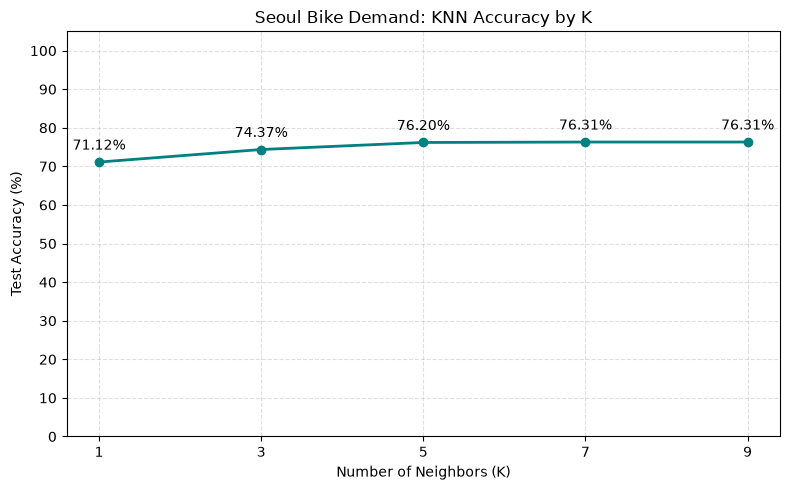

그래프 저장: knn_accuracy.png


In [7]:
def main():
    """앞에서 만든 함수들을 순서대로 연결합니다."""
    data = load_data(CSV_PATH)
    labels = make_labels(data)

    # pandas 데이터프레임을 파이썬의 2차원 리스트로 바꿉니다.
    # 예: [[0, -5.2, 37], [1, -5.5, 38], ...]
    # 이후 알고리즘은 pandas 없이 리스트와 반복문으로 처리합니다.
    features = data[FEATURE_COLUMNS].values.tolist()
    X_train, X_test, y_train, y_test = split_data(
        features, labels, train_ratio=0.8, seed=RANDOM_SEED
    )
    print(f"학습 데이터: {len(X_train):,}행 / 테스트 데이터: {len(X_test):,}행")

    minimums, maximums = get_min_max(X_train)
    X_train_scaled = min_max_normalize(X_train, minimums, maximums)
    X_test_scaled = min_max_normalize(X_test, minimums, maximums)

    print("\nKNN 계산 중입니다. 모든 테스트 행과 학습 행의 거리를 직접 계산합니다.")
    accuracies = evaluate_knn(
        X_train_scaled, y_train, X_test_scaled, y_test, K_VALUES
    )

    print("\n K    정확도")
    print("-" * 18)
    for k, accuracy in accuracies.items():
        print(f"{k:2d}    {accuracy * 100:.2f}%")

    best_accuracy = max(accuracies.values())
    best_k_values = [k for k, accuracy in accuracies.items() if accuracy == best_accuracy]
    print(f"\n이번 테스트셋 최고 정확도: K={best_k_values}, {best_accuracy * 100:.2f}%")
    plot_accuracies(accuracies, CSV_PATH.parent / "knn_accuracy.png")
    return accuracies


results = main()